In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Description:")
print(df.describe())

Dataset Shape: (2823, 25)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRE

In [4]:
# Select numerical customer-related features
X = df[['SALES', 'QUANTITYORDERED', 'PRICEEACH']].copy()

# Remove missing values
X = X.dropna()

print("Selected Features:")
print(X.head())

print("\nFeature Shape:", X.shape)

Selected Features:
     SALES  QUANTITYORDERED  PRICEEACH
0  2871.00               30      95.70
1  2765.90               34      81.35
2  3884.34               41      94.74
3  3746.70               45      83.26
4  5205.27               49     100.00

Feature Shape: (2823, 3)


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed")

Feature Scaling Completed


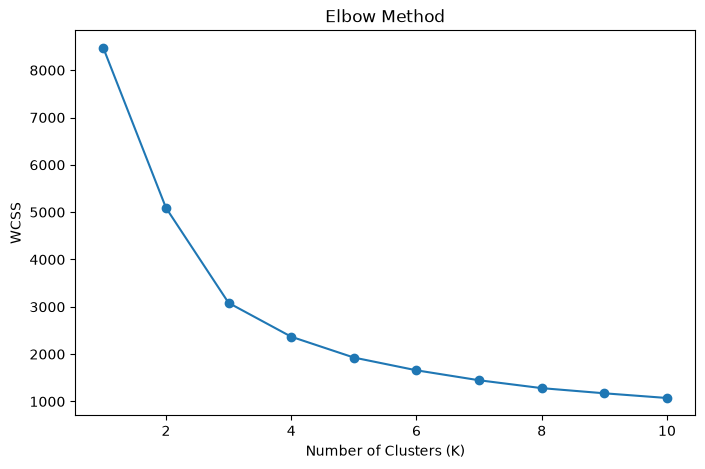

In [6]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [7]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

X['Cluster'] = clusters

print(X.head())

     SALES  QUANTITYORDERED  PRICEEACH  Cluster
0  2871.00               30      95.70        2
1  2765.90               34      81.35        2
2  3884.34               41      94.74        0
3  3746.70               45      83.26        0
4  5205.27               49     100.00        0


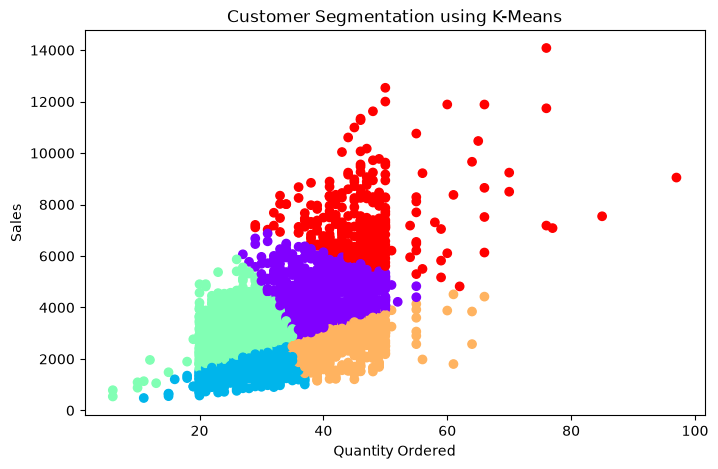

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X['QUANTITYORDERED'],
    X['SALES'],
    c=X['Cluster'],
    cmap='rainbow'
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("Customer Segmentation using K-Means")

plt.show()

In [9]:
print("Number of Customers in Each Cluster:")

print(X['Cluster'].value_counts().sort_index())

Number of Customers in Each Cluster:
Cluster
0    734
1    514
2    815
3    452
4    308
Name: count, dtype: int64


In [10]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

centers_df = pd.DataFrame(
    centers,
    columns=['SALES', 'QUANTITYORDERED', 'PRICEEACH']
)

print("Cluster Centers:")
print(centers_df)

Cluster Centers:
         SALES  QUANTITYORDERED  PRICEEACH
0  4538.273265        40.460383  95.837842
1  1579.972907        27.391473  58.055872
2  3045.881738        26.212974  96.288666
3  2562.507089        43.328889  59.267022
4  7317.315682        46.759740  99.740065
